# 📘 Pre-Workshop Notebook 1: Foundations of Brain and Behavioral Research Workflows
## Scientific Workflows for Brain and Behavioral Research
### National Science Foundation Supported Learning Initiative (Award No. OAC-2417875)

---

## 📋 Set Up Your Profile
*Run the cell below to record your name and institution in this notebook.*

In [2]:
# PROFILE SETUP
student_name = "Jade Jiaxuan Dang"
institution = "University of Missouri"
research_area = "Cognitive Neuroscience"

print(f"✅ Notebook initialized for {student_name} ({institution})")
print(f"Research area: {research_area}")

✅ Notebook initialized for Jade Jiaxuan Dang (University of Missouri)
Research area: Cognitive Neuroscience


---

## 🤖 Using AI Tools to Build Your Workflow ("Ask → Build → Document")

Welcome to a different way of learning to work with data! In this notebook, you will not be memorizing programming syntax. Instead, you will act as a **Workflow Designer** — someone who decides *what* a workflow should do and then uses AI tools (such as Claude, ChatGPT, or GitHub Copilot) to help generate the code.

To get the most out of each activity, follow this three-step cycle:
1. **Ask:** Copy the suggested prompt below into your preferred AI tool. Adjust it to fit your research area if you like.
2. **Build:** Paste the AI-generated code into the empty code cell below the prompt, then run it and look at what it produces.
3. **Document:** In the reflection box that follows, write in plain language what the code did and what it taught you about the concept.

---
## 🧠 Part A: How Brain Data Is Captured and Used
### Topic: Brain-Machine Interfaces (BMIs), Brain Imaging (fMRI), and Real-Time Systems

This section introduces two of the most important types of brain and behavioral data used in modern neuroscience research, and how analysis workflows process them.

### 🧭 Activity A.1 — Simulating a Brain-Machine Interface Decoder

> *Copy the prompt below into your preferred AI tool, then paste the generated code into the code cell beneath it.*
>
> "Act as a neuroscience research assistant helping a biology student understand brain-machine interfaces. Write a Python script using NumPy and Matplotlib that simulates how brain signals from the motor cortex can be used to control a robotic limb. The script should:
> 1. Generate 2 seconds of synthetic data representing voltage recordings from 64 brain electrodes, sampled 1000 times per second, including realistic background noise and a few sudden signal spikes representing muscle movements.
> 2. Write a simple decoding function that converts these raw voltage patterns into X and Y position coordinates representing the intended movement of a robotic limb.
> 3. Plot the raw electrode signals and the resulting decoded movement path side-by-side.
> Add plain-language comments throughout explaining what each step does and what the numbers represent."

Voltage array: (64, 2000) (electrodes × samples)


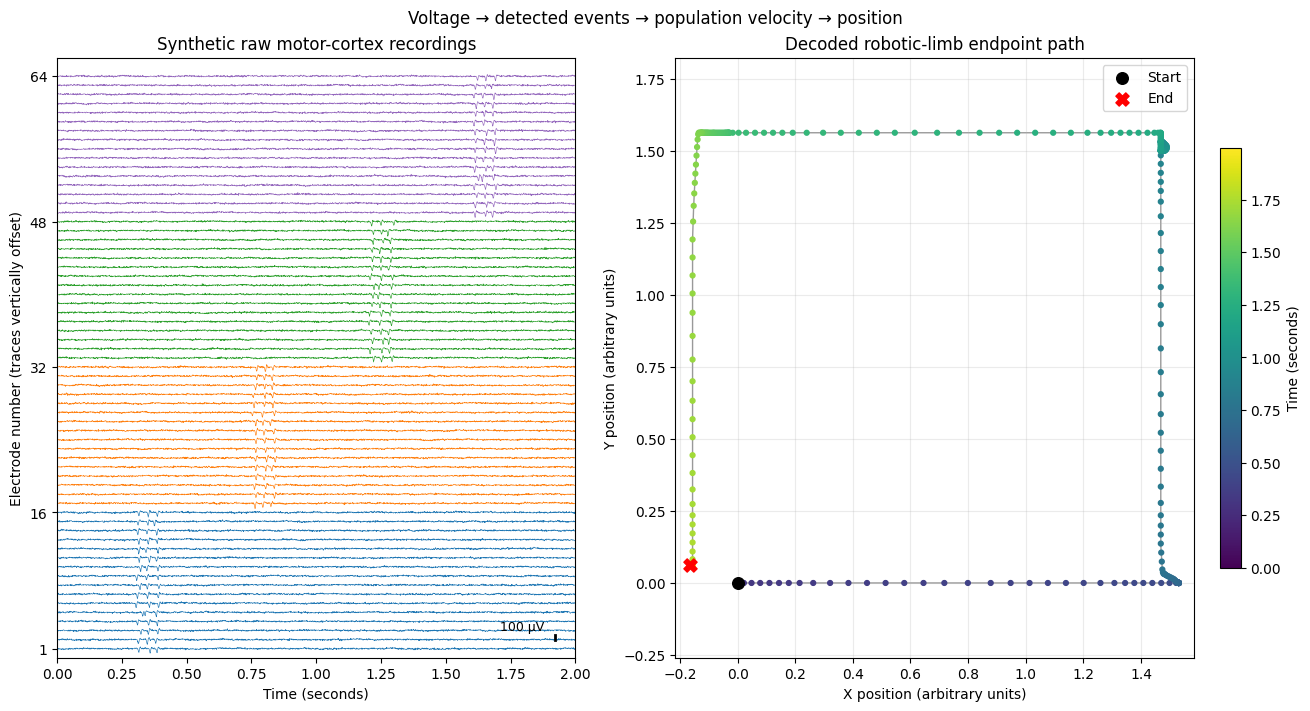

In [5]:
# 💻 Activity A.1 — Paste your AI-generated BMI Decoder code here:
"""Teaching demo: synthetic motor-cortex voltages -> robotic endpoint position.

Install: python -m pip install numpy matplotlib
Run:     python bmi_simulation.py

This is an illustrative model, not a validated neural decoder. The spikes
represent neural activity associated with intended movement, not muscle voltage.
They are deliberately broadened to be visible at 1,000 samples/second; this
sampling rate is not suitable for faithfully resolving typical neural spikes.
"""

import numpy as np
import matplotlib.pyplot as plt


def simulate_voltages(sample_rate=1000, duration=2.0, seed=7):
    """Return time, 64 voltage traces (microvolts), and direction weights."""
    rng = np.random.default_rng(seed)  # A fixed seed makes the demo repeatable.
    n_electrodes = 64
    time = np.arange(round(duration * sample_rate)) / sample_rate

    # Each row is one electrode; each column is one millisecond.
    # Mix independent electrical noise with slower, correlated fluctuations.
    white = rng.normal(0, 8, (n_electrodes, time.size))
    slow = np.zeros_like(white)
    slow[:, 0] = rng.normal(0, 5, n_electrodes)
    for k in range(1, time.size):
        slow[:, k] = 0.95 * slow[:, k - 1] + rng.normal(
            0, 5 * np.sqrt(1 - 0.95**2), n_electrodes
        )
    # A small shared 60-Hz interference component adds recording-like noise.
    voltage = white + slow + 2 * np.sin(2 * np.pi * 60 * time)

    # Four hypothetical populations prefer right, up, left, and down.
    # These assignments stand in for weights learned during real calibration.
    weights = np.repeat([[1, 0], [0, 1], [-1, 0], [0, -1]], 16, axis=0)

    # Four brief movement-related bursts occur across the two-second recording.
    # More activity in a population pushes the decoded limb in its direction.
    for center, group in zip([0.35, 0.80, 1.25, 1.65], range(4)):
        for electrode in range(16 * group, 16 * (group + 1)):
            for offset in [-0.035, 0, 0.035]:
                peak = center + offset + rng.normal(0, 0.005)
                amplitude = rng.uniform(85, 125)  # Peak size in microvolts.
                # A negative peak followed by a smaller positive rebound.
                voltage[electrode] += (
                    -amplitude * np.exp(-0.5 * ((time - peak) / 0.002)**2)
                    + 0.35 * amplitude
                    * np.exp(-0.5 * ((time - peak - 0.004) / 0.003)**2)
                )
    return time, voltage, weights


def decode_position(voltage, weights, sample_rate=1000):
    """Decode voltage into velocity, then accumulate velocity into X/Y position."""
    # Estimate background size from the first 200 ms, before any toy movement.
    baseline = voltage[:, :int(0.2 * sample_rate)]
    center = np.median(baseline, axis=1, keepdims=True)
    noise_sd = np.median(np.abs(baseline - center), axis=1) / 0.6745
    threshold = center[:, 0] - 4 * noise_sd

    # Count the beginning of each negative excursion, not every sample in it.
    below = voltage < threshold[:, None]
    events = np.zeros_like(voltage)
    events[:, 1:] = below[:, 1:] & ~below[:, :-1]

    # A causal 80-ms average uses only present and past activity.
    # Multiplying by sample_rate changes events/sample to events/second.
    window = round(0.080 * sample_rate)
    kernel = np.ones(window) / window
    rates = np.array([
        np.convolve(row, kernel, mode="full")[:voltage.shape[1]] * sample_rate
        for row in events
    ])

    # Opposing populations cancel; excess activity produces directed velocity.
    # 0.5 is an arbitrary display gain, not a biological conversion constant.
    velocity = 0.5 * (weights.T @ rates) / 16
    position = np.zeros((2, voltage.shape[1]))
    position[:, 1:] = np.cumsum(velocity[:, :-1], axis=1) / sample_rate
    return position


def main():
    time, voltage, weights = simulate_voltages()
    position = decode_position(voltage, weights)
    fig, (raw_ax, path_ax) = plt.subplots(1, 2, figsize=(13, 7),
                                          constrained_layout=True)
    colors = ["tab:blue", "tab:orange", "tab:green", "tab:purple"]

    # Show all 64 unfiltered traces, vertically offset so they remain separate.
    # One electrode spacing equals 200 microvolts; the scale bar shows 100 uV.
    for electrode in range(64):
        raw_ax.plot(time, voltage[electrode] / 200 + electrode + 1,
                    color=colors[electrode // 16], lw=0.45)
    raw_ax.plot([1.92, 1.92], [2, 2.5], color="black", lw=2)
    raw_ax.text(1.88, 3, "100 µV", ha="right", fontsize=9)
    raw_ax.set(xlim=(0, 2), ylim=(0, 66), xlabel="Time (seconds)",
               ylabel="Electrode number (traces vertically offset)",
               title="Synthetic raw motor-cortex recordings",
               yticks=[1, 16, 32, 48, 64])

    path_ax.plot(*position, color="0.6", lw=1, zorder=1)
    points = path_ax.scatter(*position[:, ::5], c=time[::5], cmap="viridis",
                             s=12, zorder=2)
    path_ax.scatter(*position[:, 0], marker="o", c="black", s=70,
                    label="Start", zorder=3)
    path_ax.scatter(*position[:, -1], marker="X", c="red", s=90,
                    label="End", zorder=3)
    path_ax.set(xlabel="X position (arbitrary units)",
                ylabel="Y position (arbitrary units)",
                title="Decoded robotic-limb endpoint path")
    path_ax.set_aspect("equal", adjustable="datalim")
    path_ax.grid(alpha=0.25)
    path_ax.legend()
    fig.colorbar(points, ax=path_ax, label="Time (seconds)", shrink=0.7)
    fig.suptitle("Voltage → detected events → population velocity → position")
    print(f"Voltage array: {voltage.shape} (electrodes × samples)")
    # Uncomment to save the figure in addition to displaying it:
    # fig.savefig("bmi_simulation.png", dpi=200)
    plt.show()


if __name__ == "__main__":
    main()

### 🧭 Activity A.2 — Simulating Brain Imaging (fMRI) Data

> *Copy the prompt below into your preferred AI tool, then paste the generated code into the code cell beneath it.*
>
> "Act as a neuroscience instructor explaining fMRI to a biology student. Write a Python script that builds a simplified simulation of a functional brain imaging dataset. The script should:
> 1. Create a small 3D grid of brain regions (10 x 10 x 10 grid points), each observed across 15 time points — representing a short fMRI recording session.
> 2. Simulate a realistic brain activity pattern where a specific region becomes active (increases its signal) and then returns to baseline, mimicking what happens when a participant performs a task.
> 3. Add a simple head movement correction step: introduce a small artificial shift in the data across time points, then show how a correction routine detects and compensates for this.
> 4. Display a plot showing how the signal changes over time in an active brain region compared to an inactive one.
> Use plain-language comments to explain what each step represents biologically."

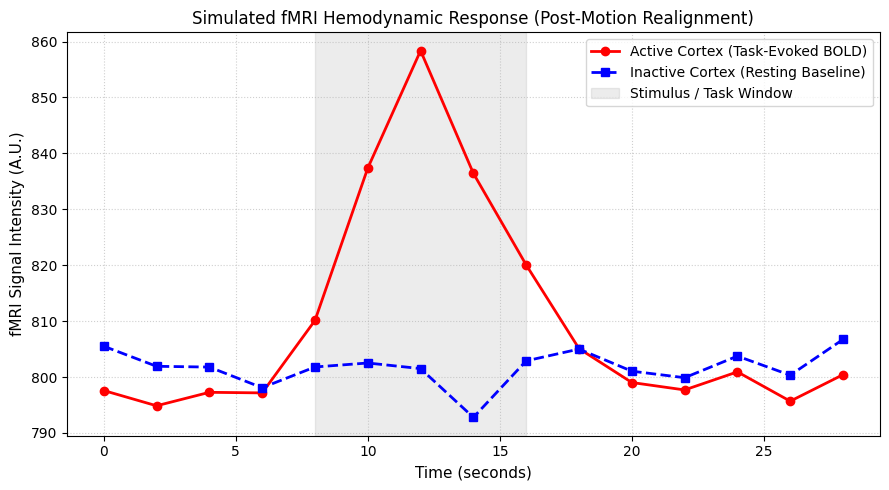

In [6]:
# 💻 Activity A.2 — Paste your AI-generated fMRI Simulation code here:
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# 1. EXPERIMENT SETUP & SYNTHETIC BRAIN GENERATION
# ==============================================================================
# Biological context:
# We divide the brain tissue into 3D volume units (voxels) arranged in a 10x10x10 grid.
# We acquire a full 3D brain snapshot (volume) every ~2 seconds across 15 time points.
grid_size = (10, 10, 10)
num_timepoints = 15

# Biological baseline: All living brain tissue has baseline blood flow and thermal
# noise from scanners. We initialize the baseline intensity with realistic noise.
np.random.seed(42)
baseline_brain = 800.0 + np.random.normal(0, 10, size=grid_size)

# Repeat baseline across all time points: Shape = (15, 10, 10, 10)
fmri_data = np.repeat(baseline_brain[np.newaxis, ...], num_timepoints, axis=0)

# Add physiological and scanner noise across the time series
fmri_data += np.random.normal(0, 15, size=fmri_data.shape)

# ==============================================================================
# 2. SIMULATING A TASK-INDUCED HEMODYNAMIC RESPONSE (BOLD SIGNAL)
# ==============================================================================
# Biological context:
# When a subject performs a task (e.g., finger tapping), local neurons fire.
# Oxygenated blood rushes to that area over 4-6 seconds before returning to baseline.
# We define an "active region" located near the center of the grid (coordinates 4:7).
active_slice = (slice(4, 7), slice(4, 7), slice(4, 7))

# Canonical BOLD response shape across the 15 time points:
# Baseline (t=0..3) -> Task onset & peak dilation (t=4..8) -> Recovery (t=9..14)
bold_profile = np.array([
    0.0, 0.0, 0.0, 0.0,      # Rest period
    15.0, 45.0, 60.0, 40.0,  # Task activation & peak arterial inflow
    20.0, 5.0, -5.0, 0.0,    # Undershoot (vessel recovery) & return to baseline
    0.0, 0.0, 0.0
])

# Inject the BOLD signal into the active region
for t in range(num_timepoints):
    fmri_data[t][active_slice] += bold_profile[t]

# Control region: an inactive brain area far from the motor task region (e.g., coordinates 0:3)
inactive_slice = (slice(0, 3), slice(0, 3), slice(0, 3))

# ==============================================================================
# 3. SIMULATING HEAD MOTION AND REALIGNMENT PREPROCESSING
# ==============================================================================
# Biological context:
# Participants often shift slightly (e.g., swallow, sigh). A 1-voxel shift
# means voxel (5,5,5) at t=8 is sampling different tissue than at t=0.
motion_start_time = 7
true_shift_x = 1  # 1 voxel shift along the X-axis starting at time point 7

corrupted_data = fmri_data.copy()
for t in range(motion_start_time, num_timepoints):
    # np.roll shifts the 3D volume along axis 1 (x-dimension)
    corrupted_data[t] = np.roll(corrupted_data[t], shift=true_shift_x, axis=0)

# --- Motion Detection and Correction ---
# In fMRI preprocessing (e.g., SPM, FSL), we register each volume back to the
# reference volume (typically t=0) by finding the shift that minimizes error.
reference_vol = corrupted_data[0]
corrected_data = np.zeros_like(corrupted_data)

for t in range(num_timepoints):
    current_vol = corrupted_data[t]

    # Test candidate shifts along the axis to find the best spatial alignment
    candidate_shifts = [-2, -1, 0, 1, 2]
    best_shift = 0
    min_difference = float('inf')

    for s in candidate_shifts:
        # Test compensating shift (-s)
        aligned_candidate = np.roll(current_vol, shift=-s, axis=0)
        # Mean squared difference relative to reference volume
        diff = np.mean((aligned_candidate - reference_vol) ** 2)
        if diff < min_difference:
            min_difference = diff
            best_shift = s

    # Apply detected correction shift to realign volume with t=0
    corrected_data[t] = np.roll(current_vol, shift=-best_shift, axis=0)

# ==============================================================================
# 4. SIGNAL EXTRACTION & VISUALIZATION
# ==============================================================================
# Extract average time series for active vs. inactive tissue across corrected data
active_signal = corrected_data[:, active_slice[0], active_slice[1], active_slice[2]].mean(axis=(1, 2, 3))
inactive_signal = corrected_data[:, inactive_slice[0], inactive_slice[1], inactive_slice[2]].mean(axis=(1, 2, 3))

# Plot the hemodynamic time courses
plt.figure(figsize=(9, 5))
time_axis = np.arange(num_timepoints) * 2.0  # Convert volumes to seconds (TR = 2.0s)

plt.plot(time_axis, active_signal, 'r-o', linewidth=2, label='Active Cortex (Task-Evoked BOLD)')
plt.plot(time_axis, inactive_signal, 'b--s', linewidth=2, label='Inactive Cortex (Resting Baseline)')

plt.axvspan(8.0, 16.0, color='gray', alpha=0.15, label='Stimulus / Task Window')
plt.title('Simulated fMRI Hemodynamic Response (Post-Motion Realignment)', fontsize=12)
plt.xlabel('Time (seconds)', fontsize=11)
plt.ylabel('fMRI Signal Intensity (A.U.)', fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### ✍️ Part A Reflection
*Double-click this cell to write your response.*

* **What I observed:** Looking at the outputs from Activities A.1 and A.2, describe how data is organized — what do the rows and columns represent in each case? What does time look like in the data?

Feature,A.1 (Electrophysiology / BMI),A.2 (fMRI Neuroimaging)
Native Shape,"2D: (Electrodes, Timepoints)","4D: (Time, X, Y, Z)"
Spatial Unit,Physical electrode sensor,3D Voxel in grid space
Temporal Sampling,1 ms bins (1000 Hz),∼2 s per volume (0.5 Hz)
Biological Metric,Action potentials / electrical potentials,Vascular BOLD response (delayed blood flow)


* **Connecting to key concepts:** Activities A.1 and A.2 demonstrate **Concepts 1, 3, 4, 5, 6, and 7** from your Reference Guide. In your own words, explain what a "decoder" does and why correcting for head movement matters before analyzing brain imaging data.

A **decoder** translates patterns of recorded brain activity into an estimate of something meaningful, such as intended movement. In our simulation, it detects sudden voltage changes across electrodes, combines activity from groups assigned to different movement directions, and converts that activity into the robotic limb’s X/Y position. In a real brain–machine interface, the relationship between neural activity and movement is usually learned from training data rather than assigned manually.

**Correcting for head movement matters because movement can change the recorded image even when brain activity has not changed.** In fMRI, each voxel represents a location in a three-dimensional image. If the head moves, the same voxel can sample different brain tissue at different times, creating apparent signal changes that could be mistaken for neural activity. Motion can also produce misleading correlations between brain regions or differences between groups. Motion correction aligns images across time, and additional steps—such as including motion estimates in the analysis or excluding heavily affected time points—help address remaining artifacts. Otherwise, a decoder or another analysis might learn patterns of head movement instead of the brain activity of interest.

---

## 💻 Part B: How Computers Store and Organize Research Data
### Topic: Working Memory, Permanent Storage, and Keeping Workflow Stages Separate

This section explores the practical computing concepts that affect how quickly and reliably a research workflow runs.

### 🧭 Activity B.1 — Comparing Working Memory and Permanent Storage

> *Copy the prompt below into your preferred AI tool, then paste the generated code into the code cell beneath it.*
>
> "Act as a computing instructor helping a biology researcher understand how computers handle data. Write a Python script that demonstrates the difference between working memory (RAM) and permanent storage (hard drive). The script should:
> 1. Measure how long it takes to read and write a large array of one million numbers directly in working memory versus saving the same data to a temporary file on disk and reading it back.
> 2. Create a loop that gradually increases the size of a data array, reporting how much working memory is being used at each step, and printing a clear warning message when memory is getting full — stopping safely before the computer runs out.
> 3. Print a clear summary comparing the speed of working memory versus disk storage.
> Use plain-language comments throughout explaining what is happening and why it matters for research workflows."

In [10]:
# 💻 Activity B.1 — Paste your AI-generated Working Memory vs. Storage code here:
"""Compare RAM with file storage, then demonstrate bounded memory growth.

Install: python -m pip install numpy psutil
Run:     python ram_vs_storage.py

No administrator privileges are needed. Temporary files are removed afterward.
RAM holds active data; files normally survive program exit until deleted.
"""

import gc
import os
from pathlib import Path
import tempfile
from time import perf_counter

import numpy as np
import psutil


MIB = 1024**2  # One MiB is 1,048,576 bytes.


def process_memory_label():
    # Some restricted cloud environments hide process information.
    try:
        rss = psutil.Process().memory_info().rss
        return f"process RSS {rss / MIB:7.1f} MiB"
    except (psutil.Error, OSError):
        return "process RSS unavailable"


def memory_status():
    """Report host RAM and, when visible, Linux container memory limits."""
    host = psutil.virtual_memory()
    capacity, available = host.total, host.available
    # A notebook/container can have a smaller allowance than its host computer.
    # Check common cgroup v2/v1 locations; unusual setups may hide these limits.
    for limit_path, used_path in [
        ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory.current"),
        ("/sys/fs/cgroup/memory/memory.limit_in_bytes",
         "/sys/fs/cgroup/memory/memory.usage_in_bytes"),
    ]:
        try:
            limit = int(Path(limit_path).read_text().strip())
            used = int(Path(used_path).read_text().strip())
        except (OSError, ValueError):
            continue  # "max" means no numerical container limit here.
        if 0 < limit < capacity:
            capacity = limit
            available = min(available, max(0, limit - used))
    return host, capacity, available


def timed(action):
    start = perf_counter()
    result = action()
    return perf_counter() - start, result


def benchmark():
    """Read/write the same 1,000,000 float64 values using RAM and a file."""
    count = 1_000_000
    # float64 uses 8 bytes per value: this array is 8 MB (about 7.63 MiB).
    needed = count * 8
    _, capacity, available = memory_status()
    reserve = max(64 * MIB, int(0.20 * capacity))
    if available - 4 * needed < reserve:
        print("WARNING: Too little memory headroom for the benchmark; skipping.")
        return

    source = np.arange(count, dtype=np.float64)
    ram_store = np.empty_like(source)
    read_buffer = np.empty_like(source)
    # Touch the buffers before timing so first-use allocation is less dominant.
    ram_store.fill(0)
    read_buffer.fill(0)
    measurements = {name: [] for name in
                    ["RAM write", "RAM read", "File write", "File read"]}

    # Use a temporary directory in the current working folder. On a normal
    # computer this is usually disk-backed; cloud systems may use RAM/network
    # storage instead. The results describe this folder's actual filesystem.
    with tempfile.TemporaryDirectory(prefix="ram_storage_demo_", dir=".") as tmp:
        path = Path(tmp) / "research_array.bin"

        def write_file():
            with path.open("wb") as handle:
                source.tofile(handle)
                handle.flush()
                # Ask the OS to finish pending writes, rather than timing only
                # a copy into its RAM cache. Hardware/filesystem behavior varies.
                os.fsync(handle.fileno())

        for _ in range(5):
            # A RAM write copies our source into a second in-memory location.
            elapsed, _ = timed(lambda: np.copyto(ram_store, source))

### 🧭 Activity B.2 — Keeping Workflow Stages Independent

> *Copy the prompt below into your preferred AI tool, then paste the generated code into the code cell beneath it.*
>
> "Act as a research software instructor. Write a Python script that demonstrates why scientific workflows should be organized into separate, independent stages — rather than one large block of code. The script should:
> 1. Stage 1 (Obtaining Data): A function that loads or generates a set of recorded sensor measurements. This function should not perform any calculations or create any plots.
> 2. Stage 2 (Analyzing Data): A function that receives the data from Stage 1 and calculates summary statistics (mean, standard deviation, range). This function should not load data or create plots.
> 3. Stage 3 (Visualizing Results): A function that takes the results from Stage 2 and creates a clean summary plot.
> Show clearly how these three stages pass information to each other, and explain in comments what would go wrong if all three were mixed together in a single block of code."

--- Stage 2 Output Metrics ---
Mean:       -0.0092 mV
Std Dev:    0.9008 mV
Range:      [-2.0138, 2.0432] mV


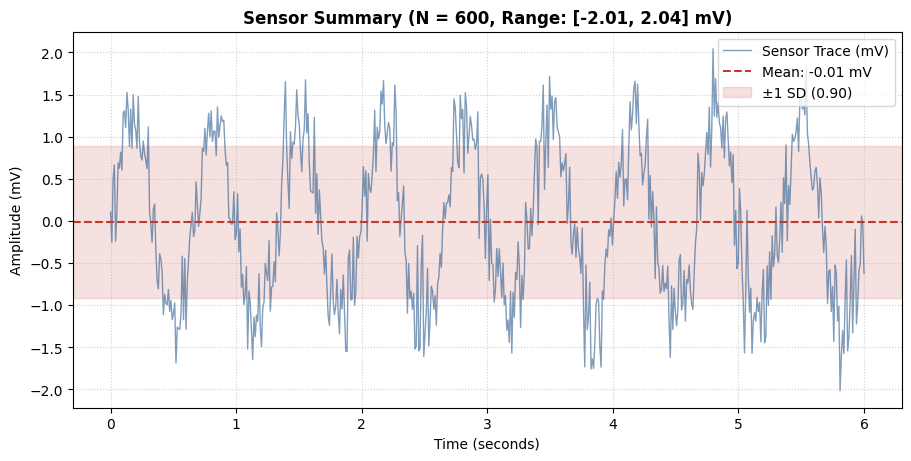

In [7]:
# 💻 Activity B.2 — Paste your AI-generated Separated Workflow Stages code here:
"""Scientific Workflow Modularization Demonstration.

Instructor Note:
Mixing data acquisition, statistical calculation, and plotting into a single
monolithic script creates tight coupling:
1. Reusability breaks: You cannot rerun statistics on pre-loaded data without
   re-reading files or re-running hardware sweeps.
2. Testing fails: Unit testing a calculation function is impossible if it
   triggers a GUI plot window or relies on external file paths.
3. Scalability collapses: Swapping storage formats (e.g., CSV to HDF5) or
   export formats (matplotlib to headless SVG/web) forces a full rewrite of
   business logic.
"""

from typing import Any, Dict
import matplotlib.pyplot as plt
import numpy as np


# ==============================================================================
# STAGE 1: Obtaining Data
# Scope: I/O or synthesis only. No math summaries, no plotting.
# ==============================================================================
def load_sensor_measurements(
    num_samples: int = 500, sampling_rate_hz: float = 100.0, seed: int = 42
) -> Dict[str, np.ndarray]:
    """Simulates raw multi-channel biosensor or physiological recording traces.

    Returns:
        dict: Raw numeric arrays containing time vector and raw channel voltages.
    """
    rng = np.random.default_rng(seed)
    time = np.linspace(0, num_samples / sampling_rate_hz, num_samples)

    # Signal = low-frequency oscillation + Gaussian sensor noise
    signal = 1.2 * np.sin(2 * np.pi * 1.5 * time) + rng.normal(
        0, 0.35, size=num_samples
    )

    return {"time_sec": time, "raw_voltage_mv": signal}


# ==============================================================================
# STAGE 2: Analyzing Data
# Scope: Pure statistical transformations. Accepts data, returns metrics.
#        Zero dependencies on file storage or display backends.
# ==============================================================================
def compute_summary_statistics(
    dataset: Dict[str, np.ndarray],
) -> Dict[str, Any]:
    """Calculates descriptive summary statistics on recorded traces.

    Args:
        dataset: Dictionary containing numeric signal arrays.

    Returns:
        dict: Processed metrics ready for reporting or plotting.
    """
    values = dataset["raw_voltage_mv"]

    mean_val = float(np.mean(values))
    std_val = float(np.std(values, ddof=1))
    val_min = float(np.min(values))
    val_max = float(np.max(values))

    return {
        "time_sec": dataset["time_sec"],
        "signal": values,
        "mean": mean_val,
        "std": std_val,
        "range": (val_min, val_max),
        "sample_count": len(values),
    }


# ==============================================================================
# STAGE 3: Visualizing Results
# Scope: Presentation layer. Consumes metrics/data structures; produces figures.
# ==============================================================================
def plot_analysis_summary(
    analysis_results: Dict[str, Any], output_path: str | None = None
) -> None:
    """Renders a diagnostic summary figure containing the raw trace and bounds."""
    time = analysis_results["time_sec"]
    signal = analysis_results["signal"]
    mean = analysis_results["mean"]
    std = analysis_results["std"]
    val_min, val_max = analysis_results["range"]

    fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")

    # Raw signal trace
    ax.plot(
        time,
        signal,
        color="#2b5c8f",
        alpha=0.6,
        linewidth=1.0,
        label="Sensor Trace (mV)",
    )

    # Summary statistic overlays
    ax.axhline(
        mean,
        color="#c0392b",
        linestyle="--",
        linewidth=1.5,
        label=f"Mean: {mean:.2f} mV",
    )
    ax.axhspan(
        mean - std,
        mean + std,
        color="#c0392b",
        alpha=0.15,
        label=f"±1 SD ({std:.2f})",
    )

    ax.set_title(
        f"Sensor Summary (N = {analysis_results['sample_count']}, Range: [{val_min:.2f}, {val_max:.2f}] mV)",
        fontsize=12,
        fontweight="bold",
    )
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude (mV)")
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper right", frameon=True)

    if output_path:
        plt.savefig(output_path, dpi=300)
    else:
        plt.show()


# ==============================================================================
# WORKFLOW ORCHESTRATION
# ==============================================================================
def run_pipeline() -> None:
    """Executes the pipeline by explicitly piping output into downstream stages."""
    # Stage 1 -> Produces raw data
    raw_data = load_sensor_measurements(num_samples=600, sampling_rate_hz=100.0)

    # Stage 2 -> Consumes raw data, produces metrics
    metrics = compute_summary_statistics(raw_data)

    # Print summary metrics independently of visualization
    print("--- Stage 2 Output Metrics ---")
    print(f"Mean:       {metrics['mean']:.4f} mV")
    print(f"Std Dev:    {metrics['std']:.4f} mV")
    print(
        f"Range:      [{metrics['range'][0]:.4f}, {metrics['range'][1]:.4f}] mV"
    )

    # Stage 3 -> Consumes metrics, produces plot
    plot_analysis_summary(metrics)


if __name__ == "__main__":
    run_pipeline()

### ✍️ Part B Reflection
*Double-click this cell to write your response.*

* **What I observed:** Based on Activity B.1, how much faster was working memory (RAM) compared to saving and loading from disk? What happened as the data size grew?

In our test, **RAM was about 3.1 times faster for writing and 2 times faster for reading**. Writing one million numbers took about **0.405 ms in RAM versus 1.255 ms to a file**; reading took **0.378 ms in RAM versus 0.750 ms from the file**. These results are specific to this run, and the file reads likely benefited from the operating system’s RAM cache, so they do not represent pure disk speeds.

As the dataset grew in **8 MiB steps**, it consumed more RAM and available memory decreased. At **128 MiB**, the script printed a warning and stopped because it reached its predefined safety budget—not because the computer was actually out of memory. It then released the allocated data.

* **Connecting to key concepts:** Activities B.1 and B.2 demonstrate **Concepts 26, 29, 36, 39, and 41** from your Reference Guide. Explain in plain language why a researcher should keep the data-loading stage of a workflow completely separate from the visualization stage.

Keeping data loading completely separate from visualization comes down to four practical realities:

1. **You will tweak plots far more often than data changes.**
Adjusting font sizes, line weights, color palettes, or axis ranges usually takes dozens of quick iterations. If loading a 4 GB recording or parsing hundreds of files is glued to the plotting code, every 2-second styling tweak forces a 30-second to 5-minute reload. Decoupling them lets you load the data once into memory (or cache summary tables) and iterate on the figure instantly.
2. **Loading is slow I/O; plotting is rendering.**
Reading large neuroimaging files, sensor traces, or tabular datasets stresses disk read speeds and memory bandwidth. Rendering a figure stresses graphic libraries and display buffers. Tying them together means an I/O hiccup (like an unstable network drive or a corrupted file index) breaks your figure generation, and a minor plotting bug (like an out-of-bounds axis limit) aborts a lengthy data read.
3. **Plots display summaries, not raw files.**
Good figures visualize aggregated metrics—means, confidence bands, effect sizes, or regression fits—rarely raw point clouds of millions of sample points. If your plotting script must parse raw files directly, you end up re-running filters, downsampling, and math transforms inside the visual layer, blurring where data processing stops and presentation begins.
4. **Batch processing on remote servers vs. local figures.**
Heavy data extraction often runs headless on a high-performance computing (HPC) cluster where no graphical display (GUI) exists. Visualization often happens locally or requires different export backends (PDF, SVG, web interactive). Keeping them independent lets you run data extraction pipelines unattended on a server and pass lightweight, standardized output files to your local plotting environment.

---

## 📑 What Comes Next

The next four pre-workshop notebooks build directly on the foundations you have established here. Notebook 2 introduces working with datasets from many participants at once. Notebook 3 covers signal cleaning and filtering. Notebook 4 introduces pattern recognition and machine learning. Notebook 5 brings everything together into a complete integrated workflow.


---

## 📖 Reference Guide: 50 Key Concepts for Neuroscience Workflows

Keep this reference guide handy throughout all five pre-workshop notebooks and during the onsite labs. These concepts form the foundation of the workshop's hands-on activities.

### 🧠 Neuroscience & Research Applications (Concepts 1–25)
1. **Brain-Machine Interface (BMI):** A system that connects the brain directly to an external device — bypassing damaged nerves or muscles — so that brain signals can control a robotic limb, cursor, or other tool.
2. **Non-Invasive (EEG) vs. Invasive (Intracortical) Sensors:** Scalp electrodes (EEG) are easy to use but pick up blurry, averaged signals through the skull. Implanted microelectrode arrays record from individual neurons with much greater precision, but require surgery.
3. **Signal Delay (Latency):** The time gap between a brain signal being recorded and a device responding to it. Delays longer than about 50–100 milliseconds feel unnatural to the user of a prosthetic device.
4. **Decoder:** A mathematical or statistical model that translates continuous brain signal patterns into a useful output — such as movement direction, cursor position, or speech intent.
5. **fMRI:** Functional Magnetic Resonance Imaging — a brain scanning method that measures blood oxygen levels as a stand-in for neural activity. When neurons become active, they consume more oxygen, causing a detectable change in the local blood signal.
6. **Voxel:** A small 3D cube of brain tissue in an fMRI image — the brain-imaging equivalent of a pixel. Each voxel contains millions of neurons.
7. **Head Movement Correction:** A processing step that aligns brain scan images across time, compensating for small movements the participant made during the recording session.
8. **Open-Loop vs. Closed-Loop Systems:** An open-loop device follows a fixed program regardless of what the user's brain is doing. A closed-loop device continuously reads incoming signals and adjusts its output in real time based on what it detects.
9. **Deep Brain Stimulation (DBS):** A treatment for conditions like Parkinson's disease in which a small implanted device delivers electrical pulses to specific brain regions to reduce tremor and improve movement.
10. **EMG (Electromyogram):** A recording of the electrical signals produced by muscles when they contract. Often used alongside brain recordings to verify whether a behavioral response actually occurred.
11. **Continuous Recordings vs. Event Markers:** A continuous recording captures an uninterrupted time series of measurements. Event markers are specific timestamps that label when something important happened — such as when a stimulus appeared or a button was pressed.
12. **Signal Drift:** The gradual change in a recorded signal over time, not due to the brain, but due to electrode movement, tissue changes, or electronic drift. Workflows need to account for this to keep analysis accurate over long sessions.
13. **Open Data Repositories:** Publicly accessible online archives (such as DANDI, OpenNeuro, or the Human Connectome Project) where researchers share their raw data so others can analyze or replicate their findings.
14. **Automated Data Download (API):** A method of downloading data directly inside a script using a standardized web link, rather than clicking through a website manually. This makes data access reproducible and audit-able.
15. **Artifact Removal:** The process of identifying and removing unwanted signals — such as electrical noise from the building, muscle movements, or eye blinks — from a raw brain recording before analysis.
16. **Downsampling:** Reducing the number of data points per second in a recording, to save memory and processing time, when the extra detail is not needed for the analysis.
17. **Standard Data Formats (BIDS):** A community-agreed system for naming and organizing brain imaging files so that any researcher or software tool can understand the structure without needing special instructions.
18. **Spectrogram:** A visual display showing how the frequency content of a signal changes over time — useful for seeing when the brain shifts between different rhythmic states such as sleep stages or attention levels.
19. **Nyquist Rule:** A fundamental rule of digital recording: to accurately capture a signal, you must record at least twice as fast as the highest frequency in that signal. Recording too slowly creates false patterns called aliasing.
20. **Local Field Potential (LFP):** An electrical recording that reflects the combined activity of a small cluster of nearby neurons — capturing the general activity level of a local brain region rather than individual cells.
21. **Signal Transfer Function:** A mathematical description of how an input signal is transformed into an output signal by a processing step — useful for predicting what a filter or decoder will do to any given input.
22. **Spike Sorting:** The process of separating a mixed electrical recording from multiple nearby neurons into individual neuron signals, based on the distinct shape of each neuron's electrical discharge.
23. **Machine Learning for Neural Decoding:** Using statistical learning algorithms to automatically find patterns in brain signal data that predict behavior, movement intent, or cognitive state.
24. **Sensory Feedback:** Sending information back to the user of a brain-machine interface — for example, delivering a gentle electrical sensation to the skin to simulate the feeling of touching an object with a prosthetic hand.
25. **Neural Plasticity:** The brain's ability to reorganize its connections over time. Relevant to BMI research because users can learn to control devices more accurately with practice as their brain adapts.

### 💻 Computing & Workflow Fundamentals (Concepts 26–50)
26. **Working Memory (RAM) vs. Permanent Storage:** RAM (working memory) holds data only while the computer is on — it is extremely fast but temporary. The hard drive stores files permanently but is much slower to access.
27. **Processor Core:** A single computing unit inside a central processor (CPU). Most modern computers have multiple cores, allowing several tasks to run at the same time.
28. **CPU vs. GPU:** A CPU handles complex, varied tasks one at a time across a few powerful cores. A GPU handles simple, repetitive tasks across thousands of smaller cores simultaneously — useful for image processing and machine learning.
29. **Memory Overflow:** What happens when a script tries to load more data into working memory (RAM) than the computer has available — causing the program to crash.
30. **Motherboard:** The main circuit board inside a computer that connects all the components — processor, memory, storage, and network — so they can communicate with each other.
31. **Processor Slowdown (Thermal Throttling):** When a processor gets too hot, it automatically slows itself down to prevent damage. This can cause unexpected slowdowns during long analysis runs.
32. **High-Speed Processor Cache:** A small, extremely fast memory area built directly into the processor, used to store frequently needed values so they do not have to be fetched from RAM repeatedly.
33. **Local vs. Cloud Computing:** Running your analysis on the computer in front of you (local) versus running it on a remote server accessed over the internet (cloud). Cloud computing allows access to much more memory and processing power.
34. **Temporary Cloud Workspace:** Cloud computing environments like Google Colab provide a temporary workspace that is automatically cleared when you close the session. Any files you need to keep must be saved to permanent storage before the session ends.
35. **Internet Speed as a Bottleneck:** When downloading large research datasets, the speed of your internet connection often limits how fast data can arrive — regardless of how fast your computer itself is.
36. **Organizing Code into Stages:** Separating a workflow into clearly defined, independent stages — such as one stage for loading data, one for analysis, and one for visualization — makes it much easier to find and fix problems.
37. **Whole Numbers vs. Decimal Numbers in Computing:** Computers store whole numbers (integers) very efficiently. Decimal numbers (floating-point) require more memory and processing time. Choosing the right type for your data can affect both speed and accuracy.
38. **Automated Data Access (API):** A standardized connection that allows one piece of software to request data or services from another automatically — for example, a script that downloads data from a research repository without any manual steps.
39. **Settings Files (JSON/YAML):** Lightweight text files used to store configuration settings, metadata, and parameters for a workflow — making it easy to share, reproduce, or adjust an analysis without changing the code itself.
40. **Processing Delay:** The time between when data arrives in your workflow and when your analysis produces a result. In real-time recording systems, keeping this delay short is critical.
41. **Keeping Stages Independent:** Designing a workflow so that the data analysis stage does not depend on the visualization stage, and vice versa. This means you can update or replace one stage without breaking the others.
42. **Text Files vs. Optimized Data Files:** Saving data as plain text (such as CSV) is easy to read in a spreadsheet but very slow for large datasets. Optimized formats (such as HDF5 or NumPy binary files) are much faster to load and take up less disk space.
43. **Simultaneous Processing (Parallel Computing):** Splitting a large task — such as analyzing 50 participants — into smaller chunks that run at the same time across multiple processor cores, rather than one after another.
44. **Hidden Configuration Settings:** Values that a workflow needs — such as access keys for a data repository — that are stored securely in the operating system rather than written directly into the code, to prevent accidental exposure.
45. **Software Libraries (Dependencies):** Pre-built collections of code (such as NumPy, SciPy, or scikit-learn) that provide ready-made tools for common tasks — so you do not have to write mathematical functions from scratch.
46. **Code Version Tracking (Git):** A system that records every change made to a set of code files over time, along with who made the change and when. This allows teams to collaborate and to restore earlier versions if something goes wrong.
47. **Error Handling:** Code that anticipates things going wrong — such as a missing file or a calculation that produces an undefined result — and responds gracefully rather than crashing the entire workflow.
48. **Data Array:** A structured list of numbers organized so that a computer can perform calculations on all of them efficiently — the basic building block of scientific data analysis.
49. **Data Backlog:** What happens when data arrives faster than your workflow can process it — causing a growing queue that eventually uses up available memory.
50. **Protecting Original Data:** A core rule of reproducible research: never modify your raw data files. Always write processed results to a new, separate file so the original record remains intact.


---

## ✅ Self-Check: What Did You Learn?

*Fill in the table below after completing both activities. Write the letter of the code cell (A.1, A.2, B.1, B.2) where your generated code best demonstrates each concept.*

| Concept Area | Concept Number | Where You Demonstrated It |
|---|---|---|
| Neuroscience | Concept 1 — What a BMI does | [ A.1 ] |
| Neuroscience | Concept 3 — Why signal delay matters | [ A.1 ] |
| Neuroscience | Concept 5 — How fMRI works | [ A.2 ] |
| Computing | Concept 26 — Working memory vs. storage | [ B.1 ] |
| Computing | Concept 36 — Organizing code into stages | [ B.2 ] |
| Computing | Concept 41 — Keeping stages independent | [ B.2 ] |
